# 11 · מדדים, אי־איזון וכיול

<div dir="rtl">

## המטרה

החזירי מילון roc_auc, pr_auc (Average Precision), brier, confusion (מטריצה 2×2 עם labels=[0,1]). סווגי probability>=threshold. כאן target=1 הוא ממאיר. דללי את קבוצת הממאירים ב־train בלבד וחשבי prevalence; השווי PR-AUC לבסיס prevalence. שרטטי ROC, PR ו־calibration curve. בחרי סף לפי מחיר FN על validation, לא על test. הוסיפי CalibratedClassifierCV על train בלבד והשווי Brier לפני/אחרי. כיול אינו מובטח להשתפר בכל חלוקה.

זמן מומלץ: 60 דקות. קראי את `data/README.md` לפני העבודה.

## הכנה

הריצי את התא הבא. הנתונים מקומיים; אין צורך להוריד אותם שוב.

</div>

**פתרון ייחוס למורה — פתיחה רק בבקשה מפורשת.**

In [1]:
from pathlib import Path
import sys
import importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.common import load
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (8, 5)
frame = load("breast_cancer")
frame.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


## העבודה שלך

השלימי את `evaluate(y_true, probability, threshold=0.5)` בקובץ `src/ex11.py`.

כתבי לפני הקוד: מה את מצפה למצוא, ואילו נתונים חסרים כדי לפרש את התוצאה?

התא הבא בטוח להרצה: הקריאה לפונקציה נשארת בהערה עד שתשלימי אותה.

In [2]:
import solutions.ex11 as student
answer = student.evaluate([0,0,1,1],[.1,.4,.6,.9])
answer

{'roc_auc': 1.0,
 'pr_auc': 1.0,
 'brier': 0.08500000000000002,
 'confusion': array([[2, 0],
        [0, 2]])}

<details><summary>רמז ראשון — לחצי רק אחרי ניסיון עצמאי</summary>

ROC משתמש בדירוג; מטריצת בלבול תלויה בסף. Brier מודד שגיאת הסתברויות.

</details>

<details><summary>רמז שני — איך להתקדם?</summary>

פתחי את הבדיקה `tests/test_ex11.py`, זהי ציפייה אחת, ונסי לממש אותה על טבלה קטנה. בקשי מהמורה שאלה מכוונת לפני קוד.

</details>

## חקירה והצגה

הוסיפי כאן את הגרפים וההשוואות שנדרשו במטרה. לכל גרף: כותרת, יחידות, מכנה ומשפט פרשנות. קוד ותוויות גרפים באנגלית; הדיון בעברית.

Train prevalence: 0.1523809523809524 test prevalence: 0.3706293706293706
raw {'roc_auc': 0.9968553459119498, 'pr_auc': 0.9955647473447402, 'brier': 0.03675130693468758, 'confusion': array([[90,  0],
       [ 9, 44]])}
calibrated {'roc_auc': 0.9970649895178197, 'pr_auc': 0.9959275920472075, 'brier': 0.055997871749409796, 'confusion': array([[90,  0],
       [12, 41]])}


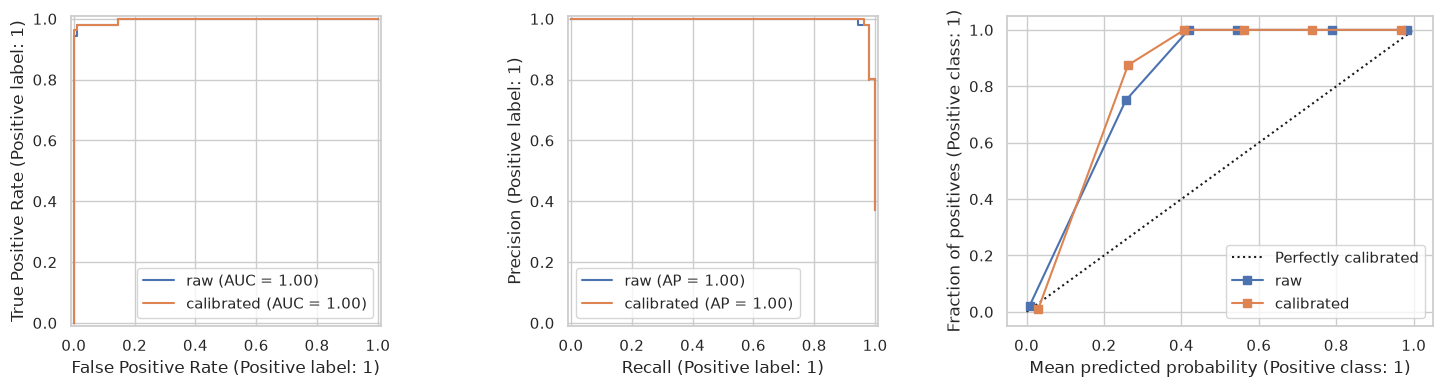

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import CalibratedClassifierCV, CalibrationDisplay
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay
X_train,X_test,y_train,y_test = train_test_split(frame.drop(columns="target"),frame.target,test_size=.25,stratify=frame.target,random_state=42)
# Reduce positives only in training; test retains its original population.
positive = y_train[y_train == 1].sample(frac=.3,random_state=42).index
keep = y_train.index[(y_train == 0) | y_train.index.isin(positive)]
X_train,y_train = X_train.loc[keep],y_train.loc[keep]
model = make_pipeline(StandardScaler(),LogisticRegression(max_iter=2000))
calibrated = CalibratedClassifierCV(model,method="sigmoid",cv=4)
model.fit(X_train,y_train); calibrated.fit(X_train,y_train)
print("Train prevalence:",y_train.mean(),"test prevalence:",y_test.mean())
fig,axes = plt.subplots(1,3,figsize=(15,4))
for name,estimator in [("raw",model),("calibrated",calibrated)]:
    probability = estimator.predict_proba(X_test)[:,1]
    print(name,student.evaluate(y_test,probability))
    RocCurveDisplay.from_predictions(y_test,probability,ax=axes[0],name=name)
    PrecisionRecallDisplay.from_predictions(y_test,probability,ax=axes[1],name=name)
    CalibrationDisplay.from_predictions(y_test,probability,ax=axes[2],name=name,n_bins=6)
fig.tight_layout()
# Threshold stays at 0.5 here; selection would require a separate validation set.


## בדיקה ומשוב

בטרמינל משורש המאגר:

```bash
make check EX=11
```

כישלון עם `NotImplementedError` צפוי לפני השלמת הפונקציה. הצלחת הבדיקות מאמתת רק את חוזה הקוד; היא אינה ציון לאיכות הניתוח.

מחוון מתוך 10: קוד ובדיקות 4; גרפים וחקירה 2; מניעת הטיות/דליפה 2; פרשנות ומגבלות 2. יעד מעבר: 8 וכל בדיקות הקוד עוברות.

## דיון למורה

יש לבסס מסקנה על הפלט שהורץ. דרשי הבחנה בין קשר וסיבתיות, תיאור אוכלוסיית המדגם והערכת הכללה. אין מסקנה קלינית הנובעת מציון גבוה בלבד. בתרגיל 11 הדילול משנה את שכיחות האימון ולכן עלול לפגוע בהעברת הכיול לאוכלוסיית המבחן. בתרגיל 12 השווי ל־dummy ובחני עד כמה החלוקה הגאוגרפית משנה את ההמלצה. אין תשובה מילולית יחידה: השתמשי במחוון שבמחברת להערכת ההנמקה.